---
This is some half-cooked fitting. Look at Reflectivity V1 for simple, or V3 for full

Doesnt use any fitting tools defined outside of this code

In [1]:
from GenPaths import * # this provides PROPATH which can help load stuff (and the paths to find the PDEhelpers stuff)

# from lmfit import Model, Parameters
# import lmfit as lm
import inspect

from scipy import optimize as opt

# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import numpy as np
import matplotlib.pyplot as plt

# from PDEhelpers import * # this causes errors because of class naming same as module naming
from PDEhelpers.PhotonInfo import *
from PDEhelpers.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d, uniform_filter
from scipy.optimize import curve_fit

from PDEhelpers import PDEStyle as MS
# MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()

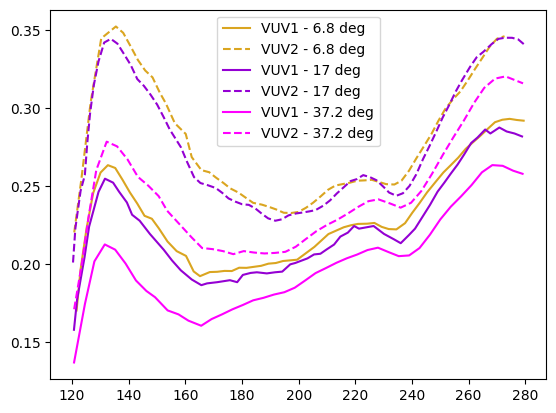

In [2]:
ms.ResetColorCycle()
fnames_refData = ["vuv_Ref_air_6d8deg.csv", "vuv_Ref_air_17deg_v2.csv", "vuv_Ref_air_37d3deg.csv"]
refData_angles = [6.8, 17, 37.2]

refData1 = [] # give the layout d1 = [x1, r1]
refData2 = []

masking = True
smoothing = False

for i in range(len(fnames_refData)):
    x1, r1, x2, r2 = np.genfromtxt(PROPATH+"literatureData/"+fnames_refData[i], skip_header= 1, delimiter=",", unpack=True)
    
    mask1 = ~np.isnan(r1)
    mask2 = ~np.isnan(r2)
    x1, r1 = x1[mask1], r1[mask1]
    x2, r2 = x2[mask2], r2[mask2]
    
    if(np.mean(r1) > 1 or np.mean(r2) > 1):
        r1 = r1/100
        r2 = r2/100
    
    # plot raw data
    plt.plot(x1, r1, color = ms.GetNextColor(), label = f"VUV1 - {refData_angles[i]} deg")
    plt.plot(x2, r2, color = ms.GetNextColor(1), linestyle = "--", label = f"VUV2 - {refData_angles[i]} deg")
    
    if smoothing:
        smoothSig = 8
        r1Int = interp1d(x1, r1, kind = "cubic", fill_value = "extrapolate")
        r2Int = interp1d(x2, r2, kind = "cubic")
        x1Vals = np.arange(min(x1), max(x1), 1)
        x2Vals = np.arange(min(x2), max(x2), 1)
        x1 = x1Vals
        x2 = x2Vals
        r1 = uniform_filter(r1Int(x1Vals), smoothSig, mode = "constant")
        r2 = uniform_filter(r2Int(x2Vals), smoothSig)
    
    if masking:
        mask1 = (x1 > 128)
        mask2 = (x2 > 128)
        x1, r1 = x1[mask1], r1[mask1]
        x2, r2 = x2[mask2], r2[mask2]
    
    refData1.append([np.array(x1), np.array(r1)])
    refData2.append([x2, r2])
    
    if smoothing:
        plt.plot(x1, r1, color = ms.GetNextColor(1), linestyle = ":", label = "Interpolated")
        plt.plot(x2, r2, color = ms.GetNextColor(1), linestyle = ":", label = "Interpolated")

plt.legend()
plt.show()

In [3]:
def ssGetNames(func):
    return inspect.getfullargspec(func).args

# class myParameter():
#     def __init__(self, name, value, error):
#         self.name = name
#         self.value = value
#         self.bounds = None
#         self.error = error

def ResultDict(fitResult, x0Names):
    resultDict = {}
    for i, key in enumerate(x0Names):
        value = fitResult.x[i]
        error = np.sqrt(fitResult.hess_inv[i, i])
        mpar = myParameter(name=key, value = value, error = error)
        resultDict[key] = mpar


# order x0 has to match the ordering in functionToFit
# therefore, this sorts the floating parameters into the correct order
def buildX0(floatDict, functionToFit):
    x0 = []
    x0Names = []
    for key in ssGetNames(functionToFit):
        if key in floatDict.keys():
            x0.append(floatDict[key])
            x0Names.append(key)
    return x0, x0Names

# ditto as above, but sorts the bounds
def buildX0_bounds(floatBoundsDict, functionToFit):
    bounds = []
    for key in ssGetNames(functionToFit):
        if key in floatBoundsDict.keys():
            bounds.append((floatBoundsDict[key][0], floatBoundsDict[key][1]))
    return bounds

# returns a copy of dict1 minus dict2 keys
def dictKeySubtraction(dict1, dict2):
    return {key: dict1[key] for key in dict1.keys() - dict2.keys()}

def listSubtraction_orderd(list1, list2):
    return [x for x in list1 if x not in list2]

def genericResiduals(x0, fixedArgs_dict, dataHeaders, dataObj, functionToFit, nuisanceResult=None, verbose = False):

    # sorted, ordered lists of args
    allArgs = ssGetNames(functionToFit)
    nonDataArgs = listSubtraction_orderd(allArgs, dataHeaders)
    missingArgs = listSubtraction_orderd(nonDataArgs, fixedArgs_dict.keys()) # this is the ordered keys that x0 correspond to
    
    print("all args minus data", nonDataArgs) if verbose else None
    print("missing args", missingArgs) if verbose else None
    
    ## length testing, ensuring enough vars are passed
    if len(x0) + len(fixedArgs_dict) != len(nonDataArgs):
        print("missing or extra args passed, len(x0) + len(fixedDict) != len(argsNeeded)")
        print("lens:", len(x0) + len(fixedArgs_dict), len(allArgs))
    
    # see what keys are missing from fixed list (these are in x0)
    if len(x0) != len(missingArgs):
        print("missing args to function does not match x0!")
        print(len(missingArgs), len(x0))
    
    # create a new dictionary with the missing keys and values from x0
    fullArgDict = fixedArgs_dict.copy()
    for i, key in enumerate(missingArgs):
        fullArgDict[key] = x0[i]
    
    if len(dataHeaders) < 2:
        print("Not enough data headers supplied!\nneed at least 2 (x and y) or other values will get broken")
    
    ## Data loop
    resSum = 0
    for i, oneD in enumerate(dataObj):
        x = oneD[0]
        y = oneD[1]
        
        # things like voltage, theta, etc here
        dataXdict = {dataHeaders[0]: x}
        otherDataDict = {key: oneD[i+2] for i, key in enumerate(dataHeaders[2:])}
        
        print(f"otherDataDict {i}", otherDataDict, "\n") if verbose else None
        # print(f"dataXdict {i}", dataXdict, "\n") if verbose else None
        print(f"fullArgDict {i}", fullArgDict, "\n") if verbose else None
        
        yFit = functionToFit(**fullArgDict, **dataXdict, **otherDataDict)
        
        resSum += np.sum((y - yFit)**2)
    
    return resSum

all args minus data ['a', 'b', 'c']
missing args ['c']
otherDataDict 0 {} 

fullArgDict 0 {'b': 0, 'a': 1.0, 'c': 5} 

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 12.1211464858787
        x: [ 5.572e+00]
      nit: 3
      jac: [ 0.000e+00]
 hess_inv: [[ 8.333e-03]]
     nfev: 8
     njev: 4
{'c': 5.572261608382553}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/optimize/_minimize.py:569: RuntimeWarning: Method BFGS cannot handle bounds.
  warn('Method %s cannot handle bounds.' % method,


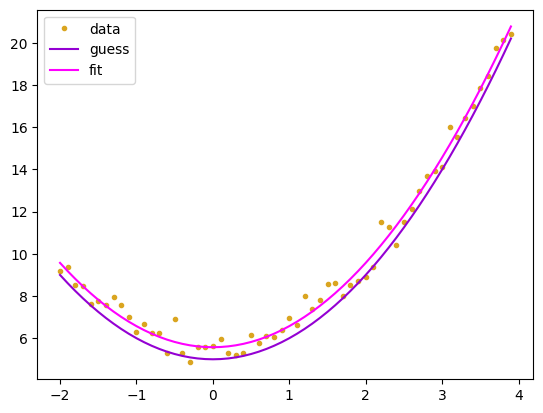

In [4]:
def testFunctionA(x, a=0, b=0, c=10):
    # print("a", a, "b", b, "c", c)
    return a*x**2 + b*x + c

ssGetNames(testFunctionA)

### -- How to use the code above --- ###

## Step 1: setup names and variables    
# if its looped over (changes for datasets, put it in here)
dataArgNames = ["x", "y"] # data headers. second isn't used but should be included

# fixed variables
fixedDict = {"b":0, "a":1.0}

# float variables
floatDict = {"c":5} # guesses
floatBounds = {"a":(0, 10)}

# dataArgNames + fixedDict + floatDict should have all the things that the fit function accepts, plus one extra for the input y data
# this should be checked in my residuals but maybe isn't
# xx need to include errors in residual and data object that gets passed around

## Step 2: sort floating parameters into ordered array and bounds
x0, x0Names = buildX0(floatDict, testFunctionA)
x0Bounds = buildX0_bounds(floatBounds, testFunctionA)

# Step 3: organize your data. It NEEDS to be formatted as [dataset1[x, y, whatever else], dataset2[x, y, whatever else], ...]
xData = np.arange(-2, 4, 0.1)
yData = 0.5+testFunctionA(x=xData, **fixedDict, **floatDict) + np.random.normal(scale=0.5, size=len(xData))
dataObj = [[xData, yData]]

## Step 4: test your function, and residual function
testFunctionA(x=xData, **fixedDict, **floatDict)
genericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataHeaders=dataArgNames, dataObj=dataObj, functionToFit=testFunctionA, verbose=True)

## Step 5: run the fit
result = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataArgNames, dataObj, testFunctionA), method='BFGS')
print(result)
resultDict = {x0Names[i]: result.x[i] for i in range(len(x0Names))}
print(resultDict)

## xx doesn't work yet
# resultPar = ResultDict(fitResult=result, x0Names=x0Names)

# resultErrors = {x0Names[i]: np.sqrt(result.hess_inv[i, i]) for i in range(len(x0Names))}
# print(resultErrors)

## Step 6: plot the results!
plt.plot(xData, yData, label = "data", marker=".", linestyle="none")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **floatDict), label = "guess")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **resultDict), label = "fit")

plt.legend()
plt.show()

In [27]:
## Doing single nuisance parameter scale down (sd1 = sd2)

def func_Ref(wlen, theta1 = 0, toxide=16.5, FF=0.7, scaleDown=0.3, gausSigma=None, dh=None):
    photon = PhotonInfo(wlen, theta_1=theta1, dataHelper=dh)
    totalRef = FF * (1-scaleDown) * photon.Wave_TotalReflection(toxide)
    
    # print("theta1", theta1, "toxide", toxide, "FF", FF, "scaleDown", scaleDown, "gausSigma", gausSigma)
    # print(theta1, toxide, FF, scaleDown)
    if gausSigma is not None and gausSigma > 0: # expensive but simple/works/robust
        stepPerSigma = 4
        stepSize = gausSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        smoothedRefVals = func_Ref(wlen=newXVals, theta1=theta1, toxide=toxide, FF=FF, scaleDown=scaleDown, gausSigma=None)
        smoothedRefVals = gaussian_filter1d(smoothedRefVals, sigma=gausSigma)
        refInt = interp1d(newXVals, smoothedRefVals, kind='linear', fill_value=0)
        return refInt(wlen)
    
    return totalRef

def func_Ref_minus(wlen, theta1 = 0, toxide=16.5, FF=0.7, scaleDown=0.3, gausSigma=None, dh=None):
    photon = PhotonInfo(wlen, theta_1=theta1, dataHelper=dh)
    totalRef = FF * (1-scaleDown) * photon.Wave_TotalReflection_minus(toxide)
    
    return totalRef

dataNames = ["wlen", "Ref", "theta1", "FF"] # data headers. second isn't used but should be included

dhFBK = OpticsData(oxideDataPath=PROPATH+"/opticsData/GoodMerged/silicon_dioxide-merged-nEXOFBK_k.txt")
OpticsData.ResetInstance()

fixedDict = {'gausSigma':None, "dh":None}
floatDict = {"toxide":15, "scaleDown":0.3}
floatBounds = {"toxide":(0.5, 250), "scaleDown":(0, 1)}

nuisancePars_dict = {"scaleDown":0.3, "scaleDown":0.3, }

x0, x0Names = buildX0(floatDict, func_Ref)
print(x0)
x0Bounds = buildX0_bounds(floatBounds, func_Ref)

FF1 = 0.6
FF2 = 0.7
refDataObj = []
data2Include=len(refData1)-1
for i, (x, y) in enumerate(refData1[:data2Include]):
    oneD = [x, y, refData_angles[i], FF1]
    refDataObj.append(oneD)
# for i, (x, y) in enumerate(refData2[:data2Include]):
#     oneD = [x, y, refData_angles[i], FF2]
#     refDataObj.append(oneD)

print(len(refDataObj))
genericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataHeaders=dataNames, dataObj=refDataObj, functionToFit=func_Ref, verbose=False)

fitOpts={'maxiter': 10000, 'ftol': 1e-9, 'gtol': 1e-9, 'eps': 1e-4}
#fitOpts={'maxiter': 100000, 'eps': 1e-8}
result = opt.minimize(genericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataNames, refDataObj, func_Ref), jac="3-point", method='L-BFGS-B', options=fitOpts)
print(result)

def GetErrorFromHess(resHessProduct):
    inv_hess = resHessProduct.todense()
    # hess = np.linalg.inv(inv_hess)
    return np.sqrt(np.diag(inv_hess))
def GetResDict(fitResult, x0Names):
    return {x0Names[i]: fitResult.x[i] for i in range(len(x0Names))}
resultDict = GetResDict(result, x0Names)

print(resultDict)
print("Errors:", GetErrorFromHess(result.hess_inv))

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling//opticsData/GoodMerged/silicon_dioxide-merged-nEXOFBK_k.txt
loaded and interpolated successfully.
-----------------------------
[15, 0.3]
2
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodM

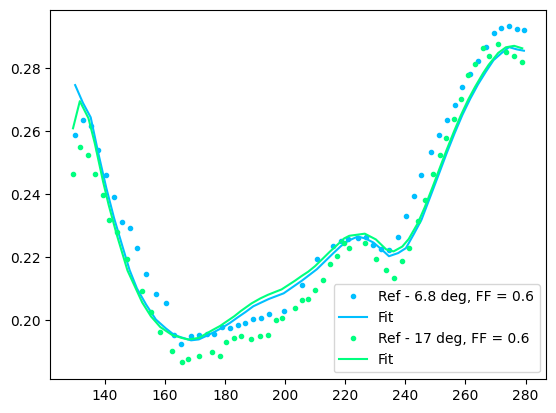

In [28]:
ms.ResetColorCycle(2)
for oneD in refDataObj:
    x = oneD[0]
    y = oneD[1]
    theta = oneD[2]
    FF = oneD[3]
    yFit = func_Ref(x, theta1=theta, FF=FF, **resultDict, **fixedDict)
    
    plt.plot(x, y, marker=".", color=ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")
    plt.plot(x, yFit, color=ms.GetNextColor(1), label = f"Fit")

plt.legend()
plt.show()

In [29]:
# for doing the full reflectivity fit, I need a wrapper function that takes two nuisane parameters.

# add nuisance parameters and mapping to my function
# a - all data (no nuisance pars), share t
# aa- fully independent (two t values)
# b - all data (1 nuisance per device)
# c - all data (1 nuisance for each dataset)
# d - discard high angle data --> trench obstruction
        # couldn't measure angle vs diffusion in paper

# try some from above with FBK k data

# try again with MINUIT


# add in Hamamatsu data? extra global fit?


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_66279/2184421639.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('rainbow', N)


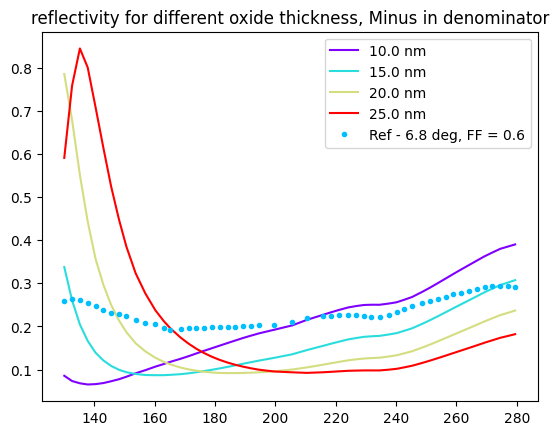

In [30]:
ms.ResetColorCycle(2)

datSingle = refDataObj[0]
x = datSingle[0]
y = datSingle[1]
theta = datSingle[2]
FF = datSingle[3]
xtoxides = np.arange(10, 30, 5)

N=len(xtoxides)
cmap = cm.get_cmap('rainbow', N)
plt.gca().set_prop_cycle(color=[cmap(i) for i in range(N)])

for t in xtoxides:
    yFit = func_Ref_minus(x, theta1=theta, FF=FF, **{"toxide":t}, **fixedDict)
    plt.plot(x, yFit, label = f"{t:0.1f} nm")

plt.plot(x, y, marker=".", color=ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")

plt.title("reflectivity for different oxide thickness, Minus in denominator")
plt.legend()
plt.show()

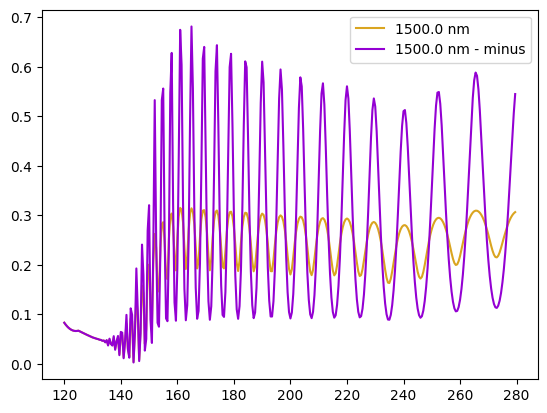

In [31]:
ms.ResetColorCycle(2)

datSingle = refDataObj[0]
x = datSingle[0]
y = datSingle[1]
theta = datSingle[2]
FF = datSingle[3]
xWlens = np.arange(120, 280, 0.5)

tThick = 1500

# N=len(xtoxides)
# cmap = cm.get_cmap('rainbow', N)
# plt.gca().set_prop_cycle(color=[cmap(i) for i in range(N)])

yFit = func_Ref(xWlens, theta1=6.6, FF=FF, **{"toxide":tThick}, **fixedDict)
yFit_minus = func_Ref_minus(xWlens, theta1=6.6, FF=FF, **{"toxide":tThick}, **fixedDict)

plt.plot(xWlens, yFit, label = f"{tThick:0.1f} nm")
plt.plot(xWlens, yFit_minus, label = f"{tThick:0.1f} nm - minus")

# plt.plot(x, y, marker=".", color=ms.GetNextColor(), linestyle="none", label = f"Ref - {theta} deg, FF = {FF}")

plt.legend()
plt.show()